# Exploratory Data Analysis: NASA C-MAPSS FD001

This notebook examines the FD001 subset of NASA's Commercial Modular Aero-Propulsion System Simulation (C-MAPSS) data. It establishes a reproducible understanding of the training data before feature engineering or machine-learning work.

## 1. Project Overview

C-MAPSS simulates multivariate sensor readings from turbofan engines as they operate and degrade. Each training engine is observed from an initial healthy state through failure. The predictive-maintenance goal is to estimate **Remaining Useful Life (RUL)**: the operating cycles remaining before failure.

FD001 is used first because it has one operating condition and one fault mode. This controlled setting is a useful baseline before addressing the additional complexity of FD002–FD004.

## 2. Imports and Configuration

A consistent visual style and plotting configuration keep the analysis readable and reproducible.

In [1]:
from pathlib import Path
import os

# Store Matplotlib's cache in a writable, project-local temporary location.
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.labelsize': 11})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

## 3. Load Dataset

The raw files have no header. The 26 canonical names match `src/data_loader.py`: engine identifier, cycle, three operating settings, and 21 sensor measurements. The raw data is read only.

In [2]:
COLUMN_NAMES = [
    'engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3',
    *[f'sensor_{number}' for number in range(1, 22)],
]

# Support execution from either the repository root or notebooks directory.
project_root = Path.cwd()
if not (project_root / 'data' / 'raw' / 'train_FD001.txt').exists():
    project_root = project_root.parent
train_path = project_root / 'data' / 'raw' / 'train_FD001.txt'
if not train_path.exists():
    raise FileNotFoundError(f'Could not find training data at {train_path.resolve()}')

df = pd.read_csv(train_path, sep=r'\s+', header=None, names=COLUMN_NAMES)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Dataset shape: 20,631 rows × 26 columns


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,"1,589.7000","1,400.6000",14.6200,21.6100,554.3600,"2,388.0600","9,046.1900",1.3000,47.4700,521.6600,"2,388.0200","8,138.6200",8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,"1,591.8200","1,403.1400",14.6200,21.6100,553.7500,"2,388.0400","9,044.0700",1.3000,47.4900,522.2800,"2,388.0700","8,131.4900",8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,"1,587.9900","1,404.2000",14.6200,21.6100,554.2600,"2,388.0800","9,052.9400",1.3000,47.2700,522.4200,"2,388.0300","8,133.2300",8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,"1,582.7900","1,401.8700",14.6200,21.6100,554.4500,"2,388.1100","9,049.4800",1.3000,47.1300,522.8600,"2,388.0800","8,133.8300",8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,"1,582.8500","1,406.2200",14.6200,21.6100,554.0000,"2,388.0600","9,055.1500",1.3000,47.2800,522.1900,"2,388.0400","8,133.8000",8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


## 4. Dataset Structure

Schema, summary statistics, and basic data-quality checks are reviewed before interpreting the data.

In [3]:
df.info()

print('\nDescriptive statistics')
display(df.describe().T)

print('Data types')
display(df.dtypes.rename('dtype').to_frame())

quality_summary = pd.DataFrame({
    'missing_values': df.isna().sum(),
    'missing_pct': df.isna().mean().mul(100),
    'unique_values': df.nunique(),
})
print('Missing-value and cardinality summary')
display(quality_summary)
print(f'Exact duplicated rows: {df.duplicated().sum():,}')

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

,count,mean,std,min,25%,50%,75%,max
engine_id,"20,631.0000",51.5066,29.2276,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,"20,631.0000",108.8079,68.8810,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,"20,631.0000",-0.0000,0.0022,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,"20,631.0000",0.0000,0.0003,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,"20,631.0000",100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,"20,631.0000",518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,"20,631.0000",642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,"20,631.0000","1,590.5231",6.1311,"1,571.0400","1,586.2600","1,590.1000","1,594.3800","1,616.9100"
sensor_4,"20,631.0000","1,408.9338",9.0006,"1,382.2500","1,402.3600","1,408.0400","1,414.5550","1,441.4900"
sensor_5,"20,631.0000",14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200


Data types


,dtype
engine_id,int64
cycle,int64
setting_1,float64
setting_2,float64
setting_3,float64
sensor_1,float64
sensor_2,float64
sensor_3,float64
sensor_4,float64
sensor_5,float64


Missing-value and cardinality summary


,missing_values,missing_pct,unique_values
engine_id,0,0.0000,100
cycle,0,0.0000,362
setting_1,0,0.0000,158
setting_2,0,0.0000,13
setting_3,0,0.0000,1
sensor_1,0,0.0000,1
sensor_2,0,0.0000,310
sensor_3,0,0.0000,3012
sensor_4,0,0.0000,4051
sensor_5,0,0.0000,1


Exact duplicated rows: 0


## 5. Engine Analysis

For the run-to-failure training set, each engine's final observed cycle is its failure cycle. The maximum cycle therefore describes its observed lifetime.

Unique engines: 100
Overall cycle range: 1 to 362


,engine_id,max_cycle
count,100.0000,100.0000
mean,50.5000,206.3100
std,29.0115,46.3427
min,1.0000,128.0000
25%,25.7500,177.0000
50%,50.5000,199.0000
75%,75.2500,229.2500
max,100.0000,362.0000


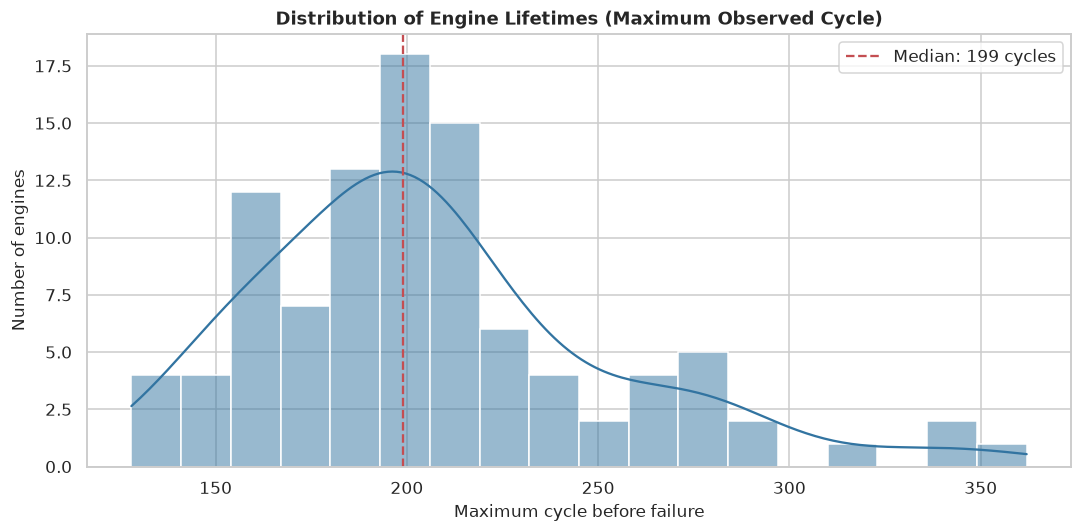

In [4]:
engine_life = (df.groupby('engine_id', as_index=False)['cycle'].max()
                 .rename(columns={'cycle': 'max_cycle'}))
print(f'Unique engines: {df.engine_id.nunique():,}')
print(f'Overall cycle range: {df.cycle.min():,} to {df.cycle.max():,}')
display(engine_life.describe())

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(engine_life['max_cycle'], bins=18, kde=True, ax=ax, color='#3274a1')
ax.axvline(engine_life['max_cycle'].median(), color='#c44e52', linestyle='--', label=f"Median: {engine_life['max_cycle'].median():.0f} cycles")
ax.set(title='Distribution of Engine Lifetimes (Maximum Observed Cycle)', xlabel='Maximum cycle before failure', ylabel='Number of engines')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Sensor and Operating Setting Analysis

FD001 is designed with a single operating condition, but the settings are inspected rather than assumed constant. All 21 sensors are summarized, low-variation sensors are flagged, and sensors are ranked by descriptive association with cycle. This is exploration, not feature selection.

In [5]:
setting_columns = [f'setting_{number}' for number in range(1, 4)]
sensor_columns = [f'sensor_{number}' for number in range(1, 22)]

print('Operating-setting summary')
display(df[setting_columns].agg(['min', 'max', 'mean', 'std', 'nunique']).T)

sensor_summary = pd.DataFrame({
    'unique_values': df[sensor_columns].nunique(),
    'minimum': df[sensor_columns].min(),
    'maximum': df[sensor_columns].max(),
    'standard_deviation': df[sensor_columns].std(),
})
sensor_summary['range'] = sensor_summary['maximum'] - sensor_summary['minimum']
sensor_summary['spearman_corr_with_cycle'] = df[sensor_columns + ['cycle']].corr(method='spearman')['cycle'].drop('cycle')
sensor_summary['abs_cycle_correlation'] = sensor_summary['spearman_corr_with_cycle'].abs()
sensor_summary = sensor_summary.sort_values('abs_cycle_correlation', ascending=False)

constant_sensors = sensor_summary.index[sensor_summary['range'].eq(0)].tolist()
near_constant_sensors = sensor_summary.index[(sensor_summary['range'].gt(0)) & (sensor_summary['standard_deviation'].le(1e-6))].tolist()
meaningful_cycle_sensors = sensor_summary.index[sensor_summary['abs_cycle_correlation'].ge(0.30)].tolist()
print(f"Constant sensors: {constant_sensors if constant_sensors else 'None'}")
print(f"Near-constant sensors (std ≤ 1e-6): {near_constant_sensors if near_constant_sensors else 'None'}")
print('Sensors with |Spearman correlation with cycle| ≥ 0.30:')
print(meaningful_cycle_sensors if meaningful_cycle_sensors else 'None at this descriptive threshold')
display(sensor_summary)

Operating-setting summary


,min,max,mean,std,nunique
setting_1,-0.0087,0.0087,-0.0000,0.0022,158.0000
setting_2,-0.0006,0.0006,0.0000,0.0003,13.0000
setting_3,100.0000,100.0000,100.0000,0.0000,1.0000


Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Near-constant sensors (std ≤ 1e-6): None
Sensors with |Spearman correlation with cycle| ≥ 0.30:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_20', 'sensor_17', 'sensor_2', 'sensor_3', 'sensor_13', 'sensor_8', 'sensor_9']


,unique_values,minimum,maximum,standard_deviation,range,spearman_corr_with_cycle,abs_cycle_correlation
sensor_11,159,46.8500,48.5300,0.2671,1.6800,0.6150,0.6150
sensor_4,4051,"1,382.2500","1,441.4900",9.0006,59.2400,0.6050,0.6050
sensor_12,427,518.6900,523.3800,0.7376,4.6900,-0.5928,0.5928
sensor_7,513,549.8500,556.0600,0.8851,6.2100,-0.5777,0.5777
sensor_15,1918,8.3249,8.5848,0.0375,0.2599,0.5708,0.5708
sensor_21,4745,22.8942,23.6184,0.1083,0.7242,-0.5695,0.5695
sensor_20,120,38.1400,39.4300,0.1807,1.2900,-0.5683,0.5683
sensor_17,13,388.0000,400.0000,1.5488,12.0000,0.5531,0.5531
sensor_2,310,641.2100,644.5300,0.5001,3.3200,0.5344,0.5344
sensor_3,3012,"1,571.0400","1,616.9100",6.1311,45.8700,0.5287,0.5287


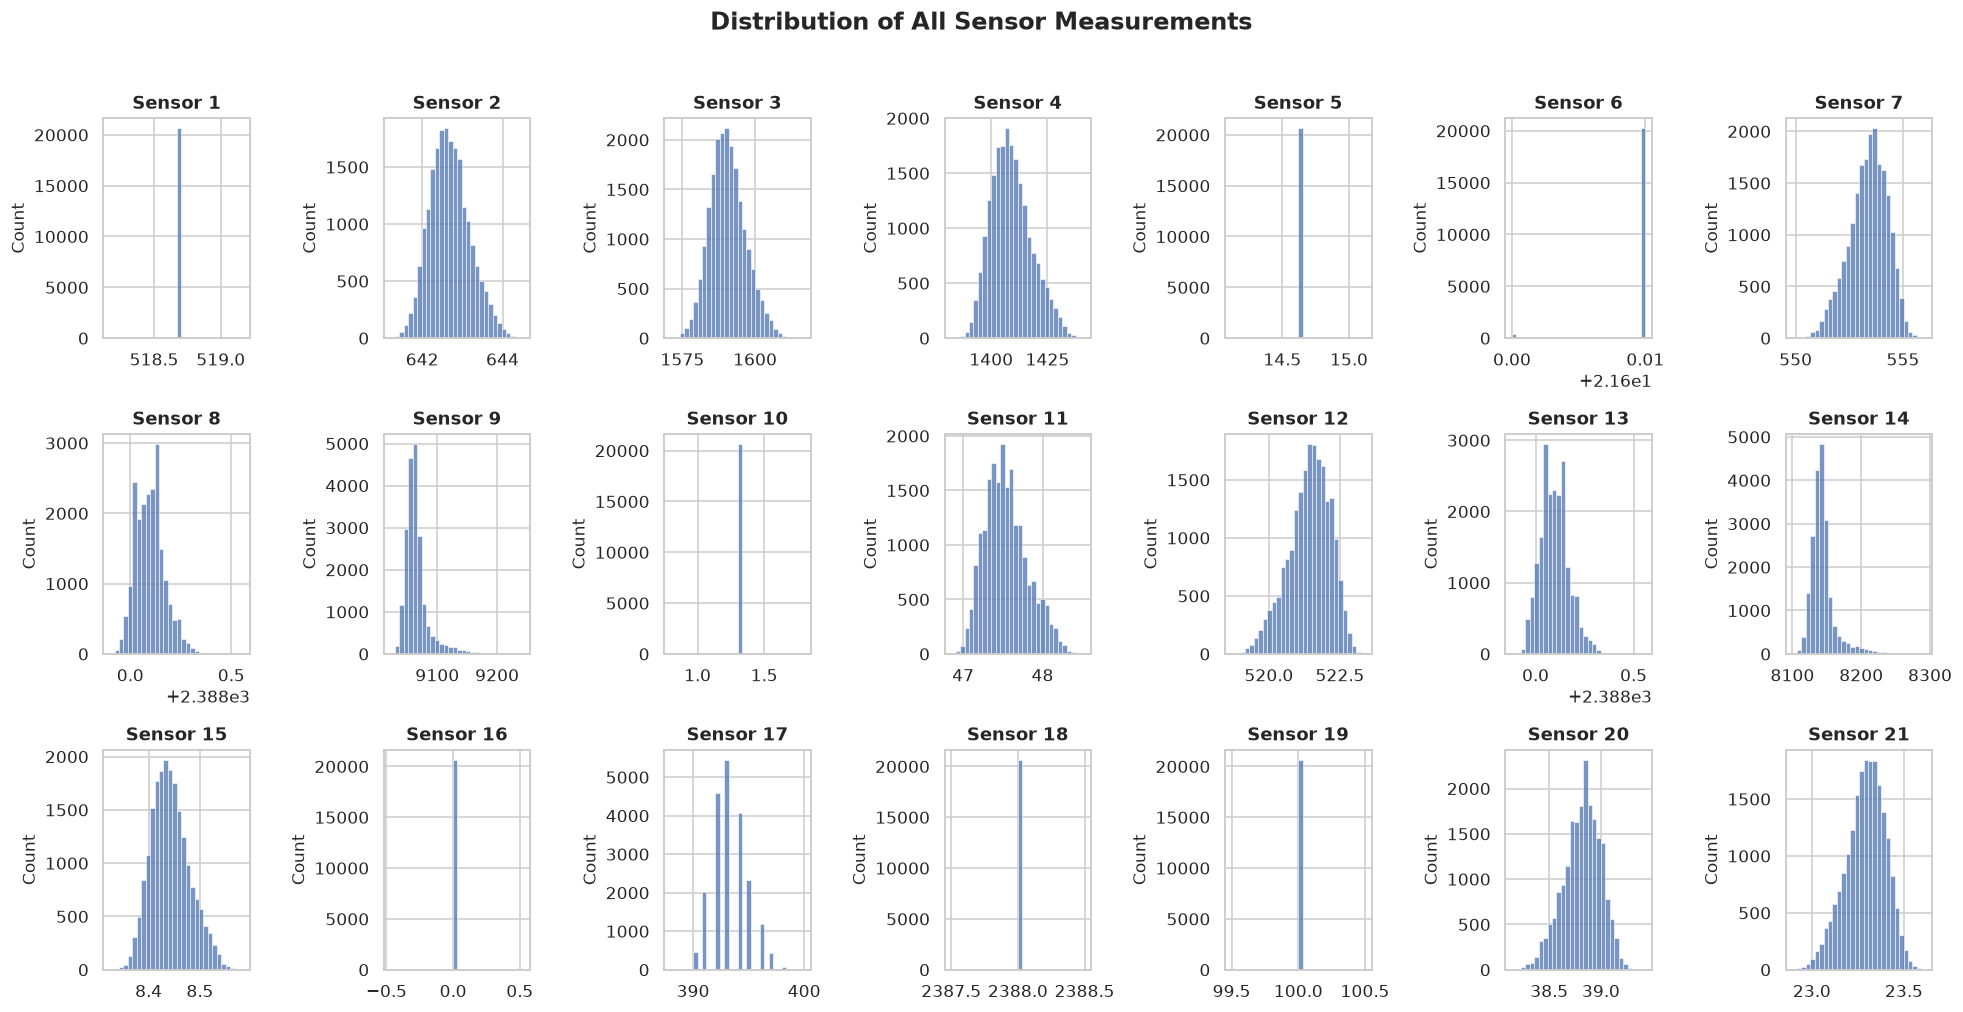

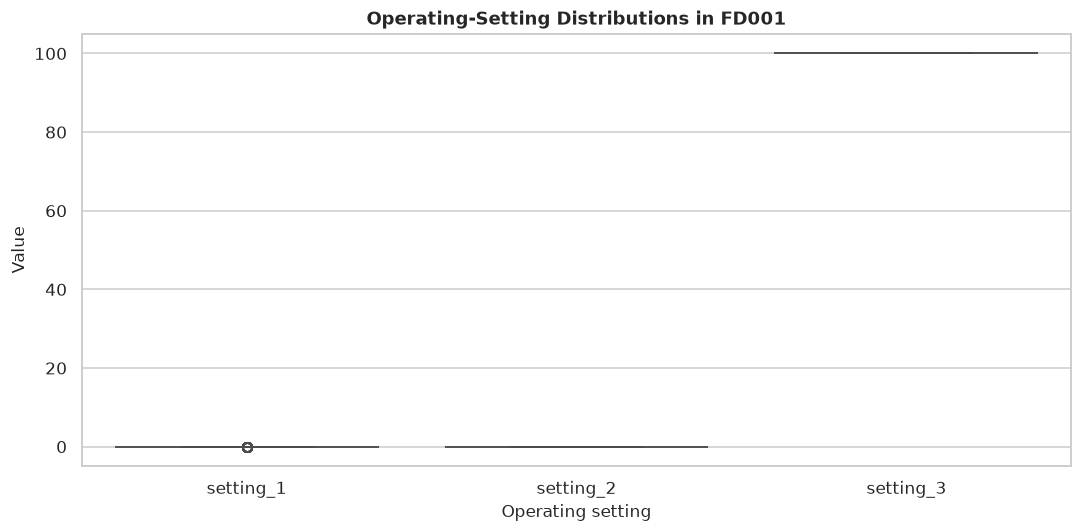

In [6]:
fig, axes = plt.subplots(3, 7, figsize=(18, 9))
for sensor, ax in zip(sensor_columns, axes.flat):
    sns.histplot(df[sensor], bins=30, ax=ax, color='#4c72b0', edgecolor=None)
    ax.set_title(sensor.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_ylabel('Count')
fig.suptitle('Distribution of All Sensor Measurements', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
settings_long = df.melt(value_vars=setting_columns, var_name='setting', value_name='value')
sns.boxplot(data=settings_long, x='setting', y='value', hue='setting', legend=False, ax=ax)
ax.set(title='Operating-Setting Distributions in FD001', xlabel='Operating setting', ylabel='Value')
plt.tight_layout()
plt.show()

## 7. Time-Series Degradation Analysis

The four non-constant sensors with the strongest absolute Spearman association with cycle are plotted for engines with short, median, and long observed lifetimes. A normalized-lifecycle view averages values by life progress, helping compare engines that fail at different cycles.

Selected sensors: ['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7']
Representative engines: [39, 69, 79]


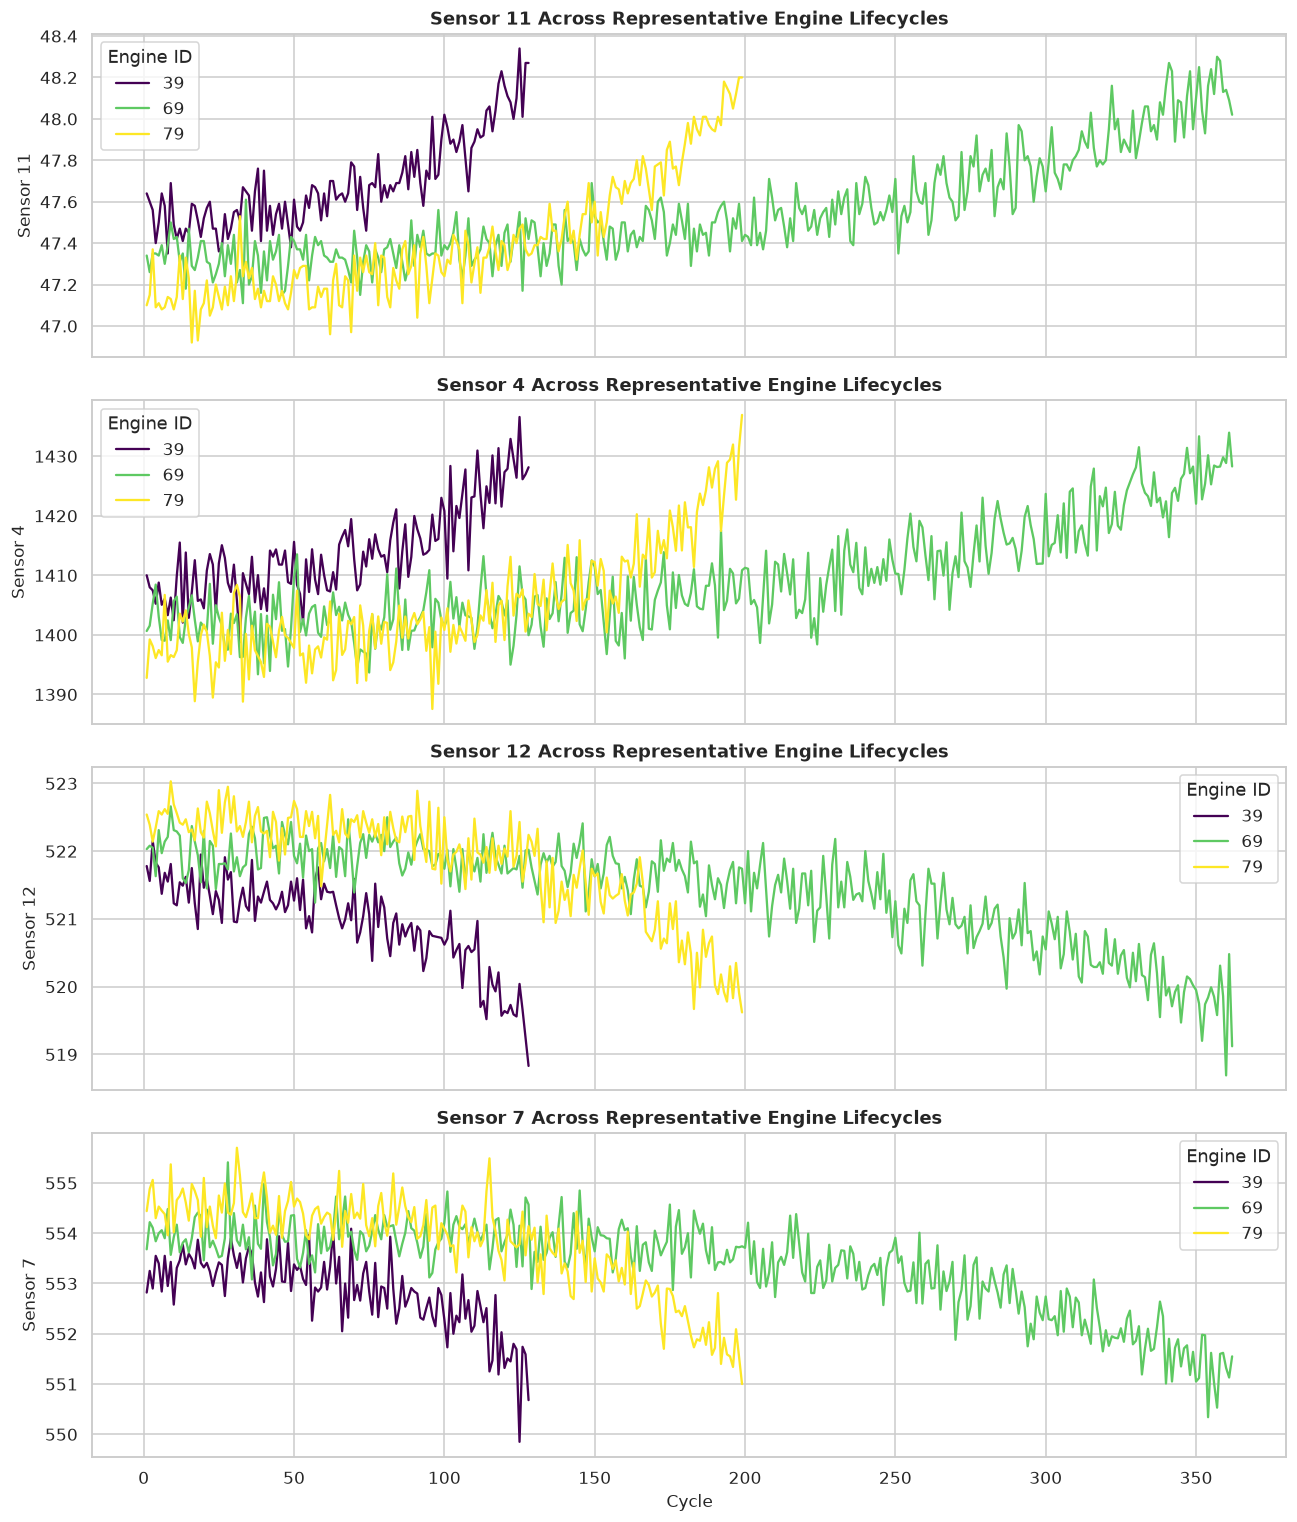

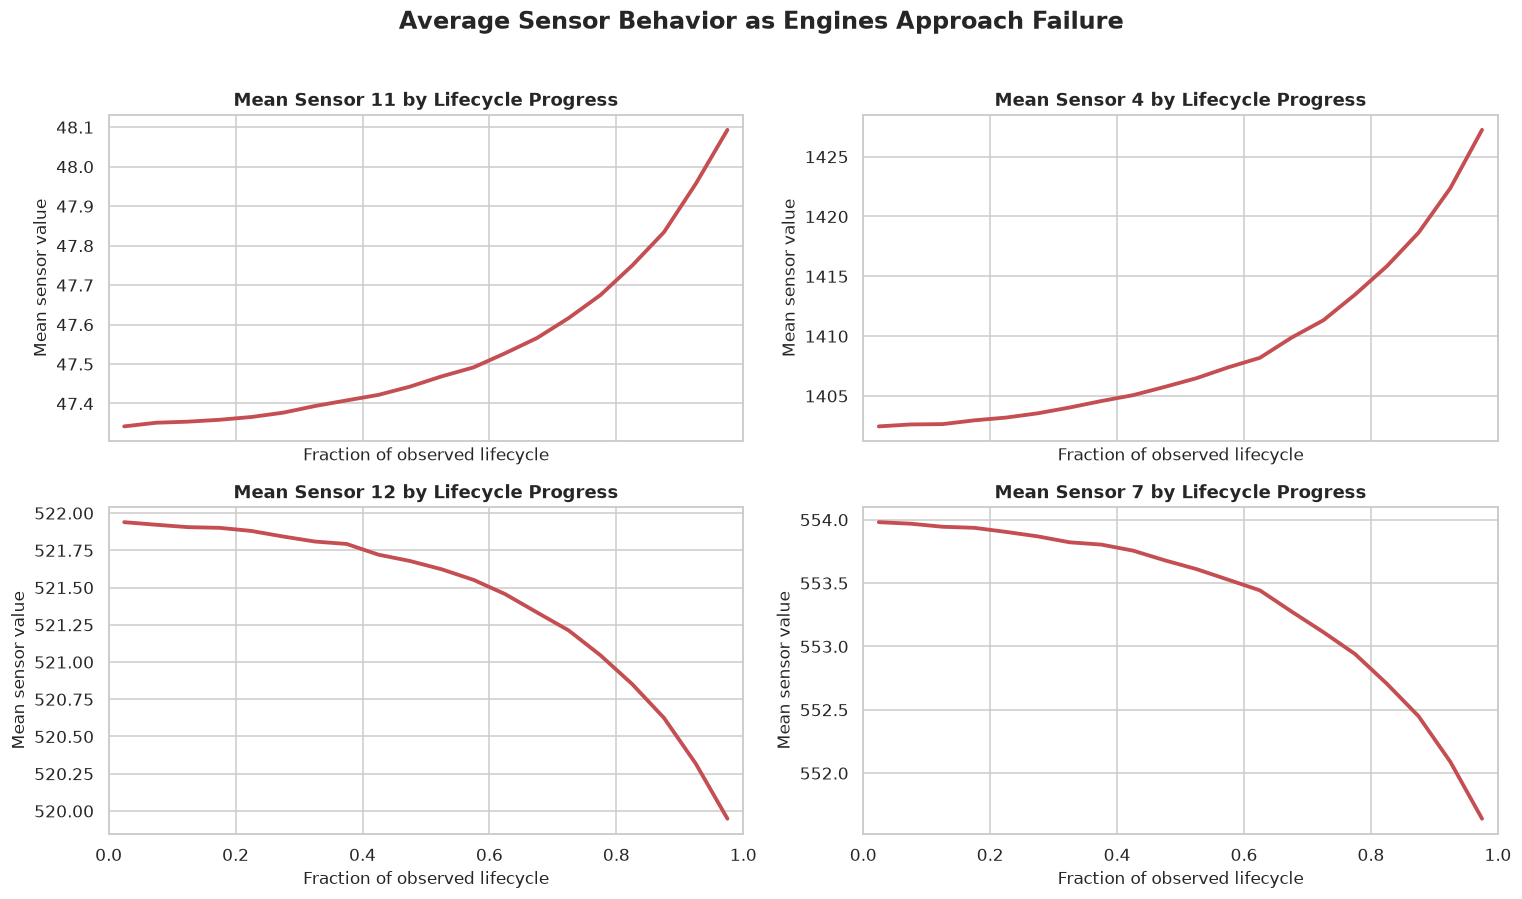

In [7]:
variable_sensor_summary = sensor_summary.loc[sensor_summary['range'].gt(0)]
selected_sensors = variable_sensor_summary.head(4).index.tolist()
life_sorted = engine_life.sort_values('max_cycle').reset_index(drop=True)
representative_engines = sorted({int(life_sorted.iloc[0]['engine_id']), int(life_sorted.iloc[len(life_sorted) // 2]['engine_id']), int(life_sorted.iloc[-1]['engine_id'])})
plot_data = df[df['engine_id'].isin(representative_engines)].copy()
print(f'Selected sensors: {selected_sensors}')
print(f'Representative engines: {representative_engines}')

fig, axes = plt.subplots(len(selected_sensors), 1, figsize=(12, 3.5 * len(selected_sensors)), sharex=True)
for sensor, ax in zip(selected_sensors, axes):
    sns.lineplot(data=plot_data, x='cycle', y=sensor, hue='engine_id', palette='viridis', ax=ax)
    ax.set(title=f'{sensor.replace('_', ' ').title()} Across Representative Engine Lifecycles', xlabel='Cycle', ylabel=sensor.replace('_', ' ').title())
    ax.legend(title='Engine ID')
plt.tight_layout()
plt.show()

lifecycle_data = df.merge(engine_life, on='engine_id', how='left')
lifecycle_data['life_fraction'] = lifecycle_data['cycle'] / lifecycle_data['max_cycle']
lifecycle_data['life_bin'] = pd.cut(lifecycle_data['life_fraction'], bins=np.linspace(0, 1, 21), include_lowest=True)
mean_lifecycle = lifecycle_data.groupby('life_bin', observed=True)[selected_sensors].mean()
mean_lifecycle.index = mean_lifecycle.index.map(lambda interval: interval.mid)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for sensor, ax in zip(selected_sensors, axes.flat):
    ax.plot(mean_lifecycle.index, mean_lifecycle[sensor], color='#c44e52', linewidth=2.5)
    ax.set(title=f'Mean {sensor.replace('_', ' ').title()} by Lifecycle Progress', xlabel='Fraction of observed lifecycle', ylabel='Mean sensor value')
    ax.set_xlim(0, 1)
fig.suptitle('Average Sensor Behavior as Engines Approach Failure', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Correlation Analysis

The heatmap displays linear correlations among numerical variables. It is a descriptive screen for co-movement, not evidence of causality or a final feature set. The ranked cycle correlations provide compact context for lifecycle relationships.

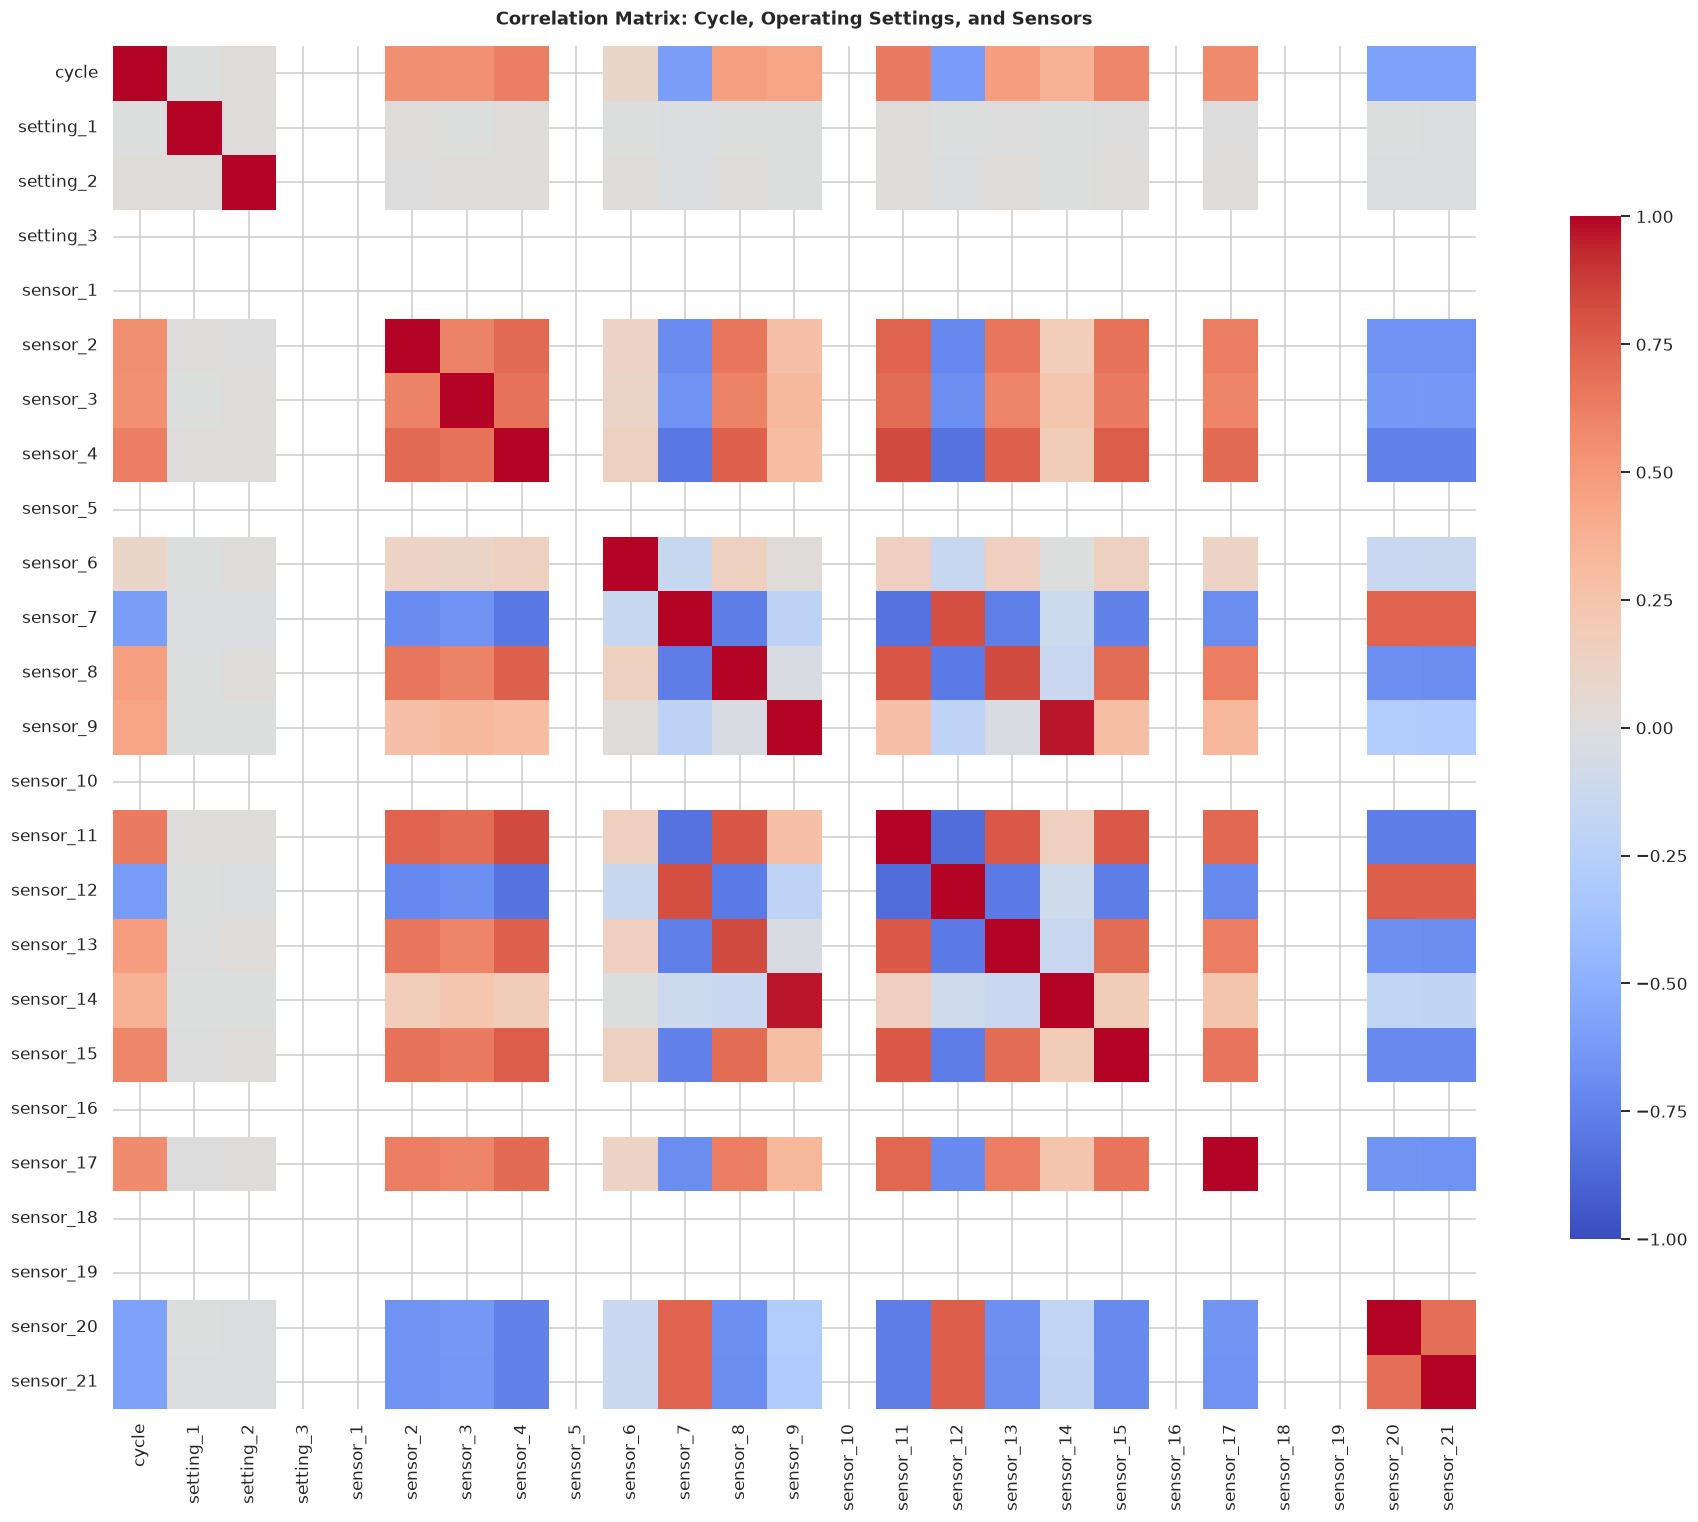

Variables with the strongest Pearson correlation with cycle:


,pearson_correlation_with_cycle
sensor_11,0.6344
sensor_4,0.6246
sensor_12,-0.6114
sensor_7,-0.5959
sensor_15,0.5887
sensor_21,-0.5859
sensor_20,-0.5836
sensor_17,0.5670
sensor_2,0.5499
sensor_3,0.5439


In [8]:
correlation_columns = ['cycle', *setting_columns, *sensor_columns]
corr_matrix = df[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={'shrink': 0.75})
ax.set_title('Correlation Matrix: Cycle, Operating Settings, and Sensors', pad=14)
plt.tight_layout()
plt.show()

cycle_correlations = corr_matrix['cycle'].drop('cycle').sort_values(key=np.abs, ascending=False)
print('Variables with the strongest Pearson correlation with cycle:')
display(cycle_correlations.head(10).rename('pearson_correlation_with_cycle').to_frame())

## 9. Initial RUL Construction

For run-to-failure training data, the standard convention is:

\[\text{RUL} = \max(\text{cycle for engine}) - \text{current cycle}\]

The temporary `RUL` column below exists only in memory for EDA; the raw training file remains unchanged.

RUL range: 0 to 361 cycles


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


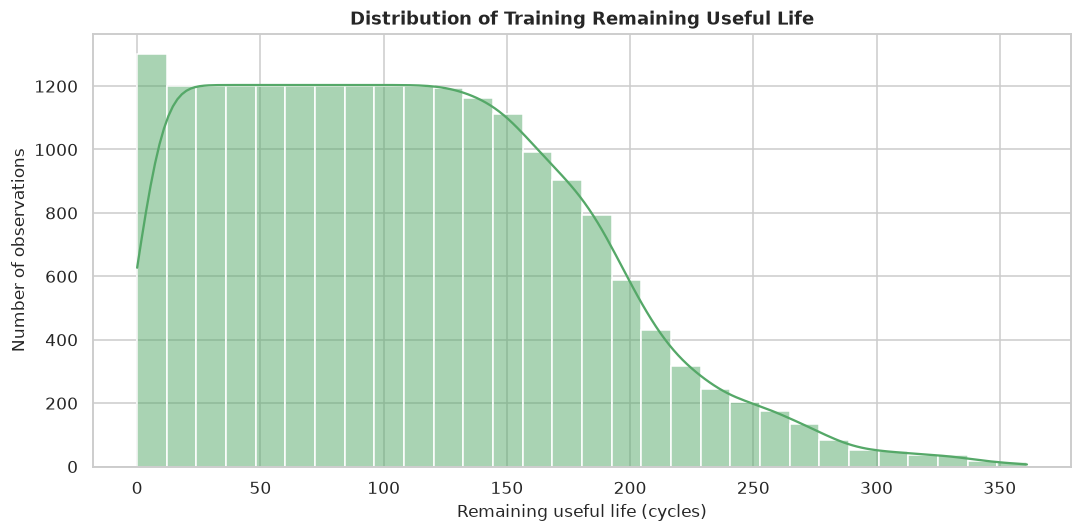

Sensors with the strongest Spearman association with temporary training RUL:


,spearman_correlation_with_RUL
sensor_11,-0.7181
sensor_4,-0.7018
sensor_12,0.6931
sensor_7,0.6788
sensor_15,-0.6659
sensor_21,0.6574
sensor_20,0.6533
sensor_17,-0.6294
sensor_2,-0.6286
sensor_3,-0.6056


In [9]:
df_eda = df.copy()
df_eda['RUL'] = df_eda.groupby('engine_id')['cycle'].transform('max') - df_eda['cycle']
print(f'RUL range: {df_eda.RUL.min():,} to {df_eda.RUL.max():,} cycles')
display(df_eda[['engine_id', 'cycle', 'RUL']].head())

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_eda['RUL'], bins=30, kde=True, color='#55a868', ax=ax)
ax.set(title='Distribution of Training Remaining Useful Life', xlabel='Remaining useful life (cycles)', ylabel='Number of observations')
plt.tight_layout()
plt.show()

rul_correlations = df_eda[sensor_columns + ['RUL']].corr(method='spearman')['RUL'].drop('RUL').sort_values(key=np.abs, ascending=False)
print('Sensors with the strongest Spearman association with temporary training RUL:')
display(rul_correlations.head(10).rename('spearman_correlation_with_RUL').to_frame())

## 10. Key EDA Findings

This calculated summary is intentionally descriptive: it documents what is present in FD001 without prescribing a model or a final feature set.

In [10]:
strongest_rul_sensors = rul_correlations.head(5)
constant_text = ', '.join(constant_sensors) if constant_sensors else 'none'
near_constant_text = ', '.join(near_constant_sensors) if near_constant_sensors else 'none'
strongest_text = ', '.join(f'{sensor} ({value:+.2f})' for sensor, value in strongest_rul_sensors.items())
summary = f"""
- **Coverage:** FD001 contains **{len(df_eda):,} observations** from **{df_eda.engine_id.nunique()} engines**. Observed engine lifetimes range from **{engine_life.max_cycle.min()}** to **{engine_life.max_cycle.max()} cycles**.
- **Data quality:** There are **{df_eda.isna().sum().sum()} missing values** and **{df_eda.duplicated().sum()} exact duplicated rows**.
- **Operating settings:** Their observed distributions are reported above; this validates inspecting FD001 as a single-condition baseline rather than relying solely on its label.
- **Low-variation sensors:** Constant sensors are **{constant_text}**. Near-constant sensors under the stated threshold are **{near_constant_text}**.
- **Potential degradation information:** The strongest descriptive Spearman associations with temporary RUL are **{strongest_text}**. These merit further investigation, not final selection.
- **Target convention:** Temporary training RUL reaches zero at each engine's final observed cycle. No raw dataset file was modified.
"""
display(Markdown(summary))


- **Coverage:** FD001 contains **20,631 observations** from **100 engines**. Observed engine lifetimes range from **128** to **362 cycles**.
- **Data quality:** There are **0 missing values** and **0 exact duplicated rows**.
- **Operating settings:** Their observed distributions are reported above; this validates inspecting FD001 as a single-condition baseline rather than relying solely on its label.
- **Low-variation sensors:** Constant sensors are **sensor_1, sensor_5, sensor_10, sensor_16, sensor_18, sensor_19**. Near-constant sensors under the stated threshold are **none**.
- **Potential degradation information:** The strongest descriptive Spearman associations with temporary RUL are **sensor_11 (-0.72), sensor_4 (-0.70), sensor_12 (+0.69), sensor_7 (+0.68), sensor_15 (-0.67)**. These merit further investigation, not final selection.
- **Target convention:** Temporary training RUL reaches zero at each engine's final observed cycle. No raw dataset file was modified.
